# Proyek Akhir: Menyelesaikan Permasalahan Human Resources
## Jaya Jaya Maju

- Nama: Salzabila Triana Said
- Email: strianasaid@gmail.com
- Id Dicoding: zalana9

## Persiapan

### Menyiapkan library yang dibutuhkan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)
import joblib

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

### Menyiapkan data yang akan digunakan

In [ ]:
df = pd.read_csv("employee_data.csv")
print(df.shape)
df.head()

(1470, 35)


,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,...,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,...,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,...,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,...,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,...,2,80,3,20,2,3,5,3,0,2


## Data Understanding

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   str    
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   str    
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   str    
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   str    
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel           

In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
EmployeeId,1470.0,NaN,NaN,NaN,735.5,424.496761,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1058.0,NaN,NaN,NaN,0.169187,0.375094,0.0,0.0,0.0,0.0,1.0
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
# Cek missing value pada setiap kolom
df.isna().sum()[df.isna().sum() > 0]

Attrition    412
dtype: int64

Kolom `Attrition` memiliki **412 baris kosong**. Baris-baris ini merupakan karyawan yang statusnya (masih bekerja / resign) belum diketahui, dan akan diprediksi menggunakan model machine learning yang dibangun dari 1.058 baris berlabel.

In [ ]:
labeled = df[df["Attrition"].notna()].copy()
unlabeled = df[df["Attrition"].isna()].copy()
print("Data berlabel :", labeled.shape)
print("Data belum berlabel (perlu diprediksi):", unlabeled.shape)

attrition_rate = labeled["Attrition"].mean() * 100
print(f"\nAttrition rate pada data berlabel: {attrition_rate:.2f}%")

Data berlabel : (1058, 35)
Data belum berlabel (perlu diprediksi): (412, 35)

Attrition rate pada data berlabel: 16.92%


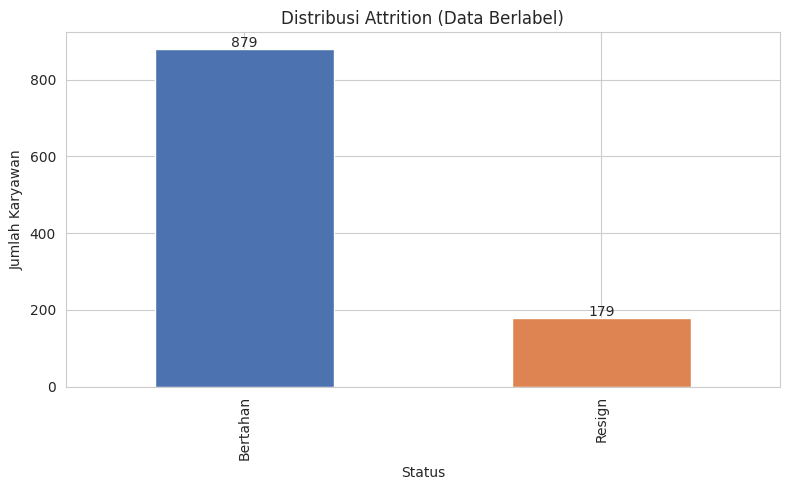

In [ ]:
# Distribusi target
ax = labeled["Attrition"].map({0: "Bertahan", 1: "Resign"}).value_counts().plot(
    kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_title("Distribusi Attrition (Data Berlabel)")
ax.set_xlabel("Status")
ax.set_ylabel("Jumlah Karyawan")
for i, v in enumerate(labeled["Attrition"].map({0: "Bertahan", 1: "Resign"}).value_counts()):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.savefig("dashboard_assets_attrition_dist.png", dpi=120)
plt.show()

### Eksplorasi faktor-faktor yang berhubungan dengan Attrition

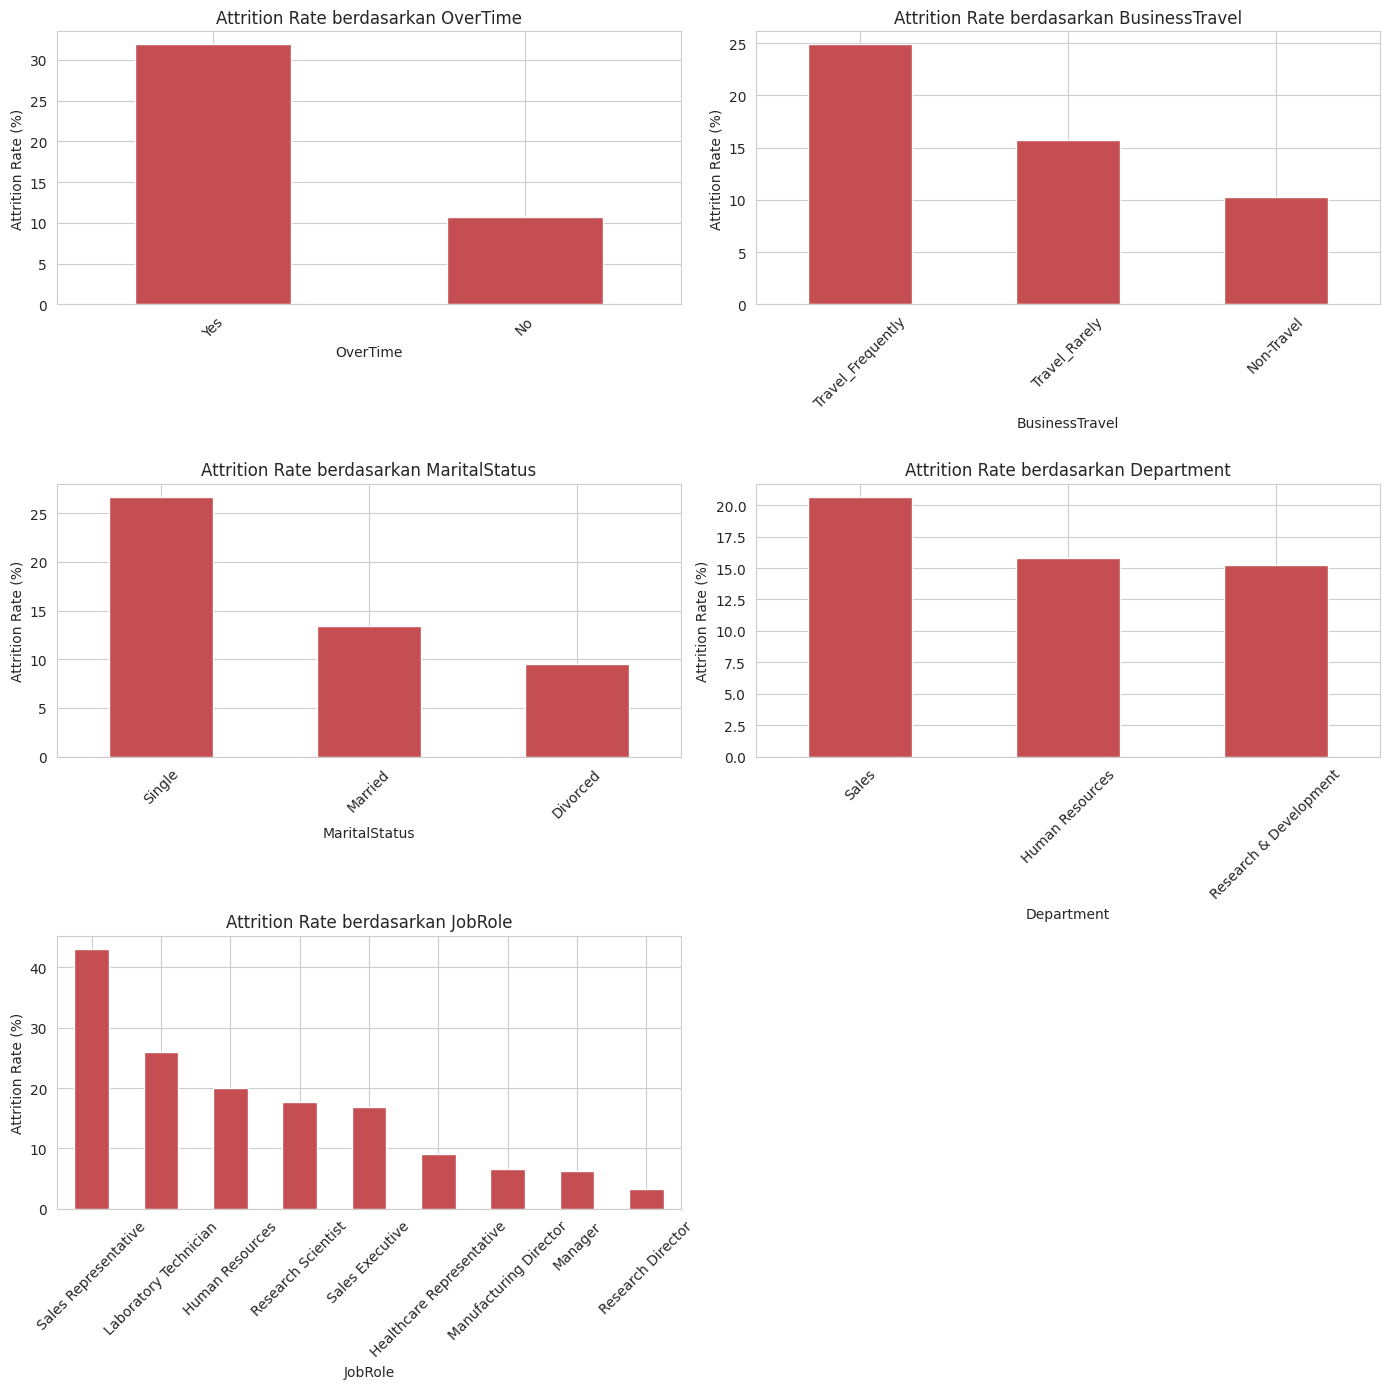

In [ ]:
cat_cols = ["OverTime", "BusinessTravel", "MaritalStatus", "Department", "JobRole"]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    rate = labeled.groupby(col)["Attrition"].mean().sort_values(ascending=False) * 100
    rate.plot(kind="bar", ax=axes[i], color="#C44E52")
    axes[i].set_title(f"Attrition Rate berdasarkan {col}")
    axes[i].set_ylabel("Attrition Rate (%)")
    axes[i].tick_params(axis="x", rotation=45)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig("dashboard_assets_categorical.png", dpi=120)
plt.show()

/tmp/ipykernel_145/2646334727.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=labeled, x="Attrition", y=col, ax=axes[i], palette=["#4C72B0", "#DD8452"])
/tmp/ipykernel_145/2646334727.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["Bertahan", "Resign"])
/tmp/ipykernel_145/2646334727.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=labeled, x="Attrition", y=col, ax=axes[i], palette=["#4C72B0", "#DD8452"])
/tmp/ipykernel_145/2646334727.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocat

/tmp/ipykernel_145/2646334727.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=labeled, x="Attrition", y=col, ax=axes[i], palette=["#4C72B0", "#DD8452"])
/tmp/ipykernel_145/2646334727.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["Bertahan", "Resign"])


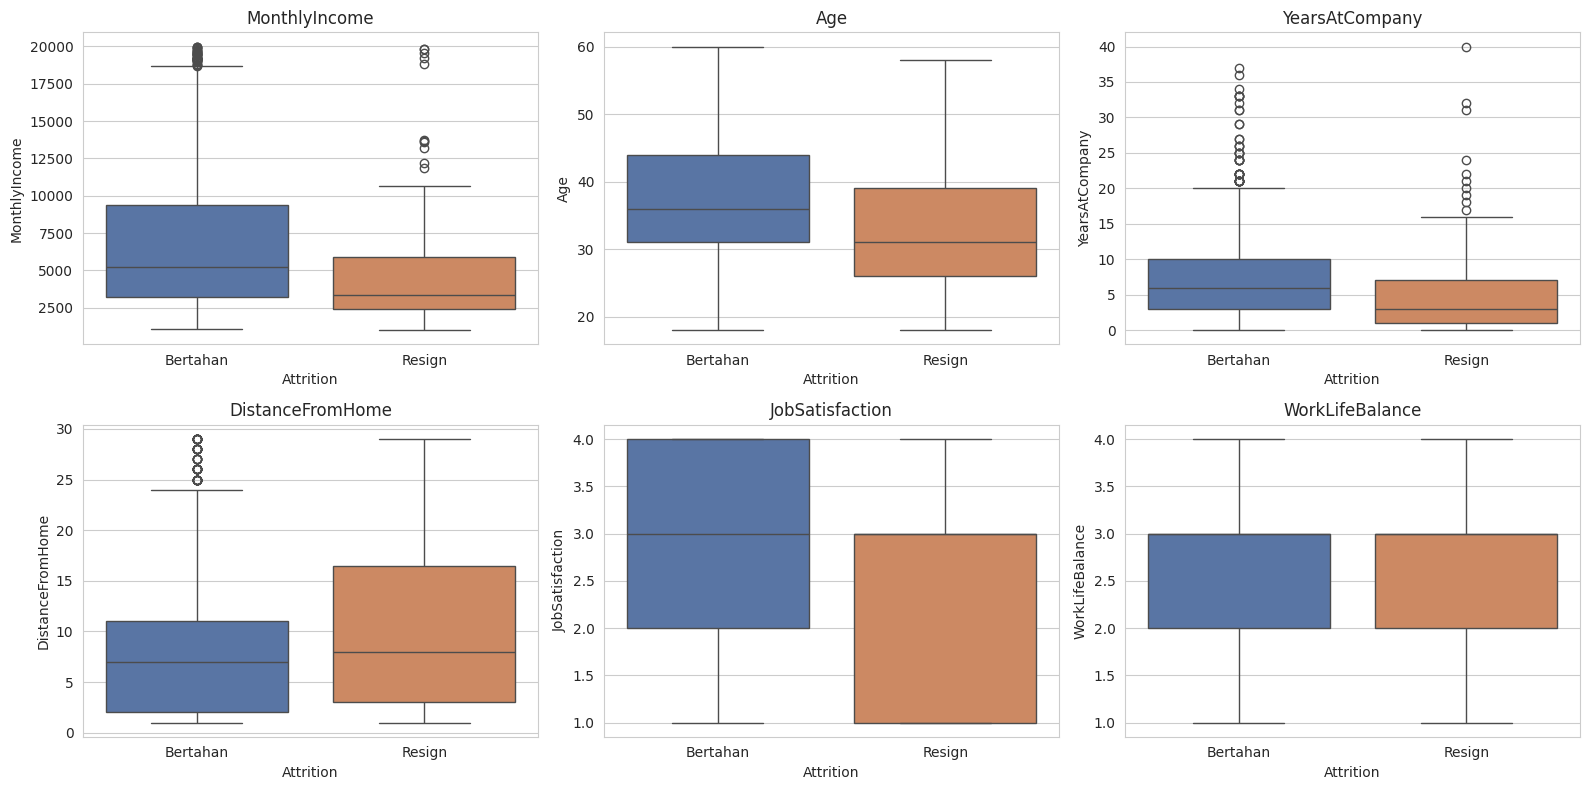

In [ ]:
num_cols = ["MonthlyIncome", "Age", "YearsAtCompany", "DistanceFromHome",
            "JobSatisfaction", "WorkLifeBalance"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=labeled, x="Attrition", y=col, ax=axes[i], palette=["#4C72B0", "#DD8452"])
    axes[i].set_xticklabels(["Bertahan", "Resign"])
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig("dashboard_assets_numerical.png", dpi=120)
plt.show()

In [ ]:
# Ringkasan rata-rata metrik kunci per status attrition
summary = labeled.groupby("Attrition")[num_cols].mean().rename(
    index={0.0: "Bertahan", 1.0: "Resign"})
summary

,MonthlyIncome,Age,YearsAtCompany,DistanceFromHome,JobSatisfaction,WorkLifeBalance
Attrition,,,,,,
Bertahan,6982.928328,37.786121,7.447099,8.695108,2.795222,2.782708
Resign,4872.938547,33.469274,5.189944,10.368715,2.525140,2.670391


**Insight awal dari Data Understanding:**
- Karyawan yang lembur (`OverTime = Yes`) memiliki attrition rate **~32%**, jauh lebih tinggi dibanding yang tidak lembur (~11%).
- `JobRole` **Sales Representative** memiliki attrition rate tertinggi (~43%), diikuti **Laboratory Technician** (~26%).
- Karyawan **Single** lebih rentan resign (~27%) dibanding yang **Married** (~13%) atau **Divorced** (~10%).
- Karyawan yang sering melakukan perjalanan dinas (`Travel_Frequently`) memiliki attrition rate ~25%, dibanding ~10% pada `Non-Travel`.
- Karyawan yang resign cenderung memiliki `MonthlyIncome` lebih rendah, masa kerja (`YearsAtCompany`) lebih singkat, usia lebih muda, dan jarak rumah ke kantor lebih jauh.

## Data Preparation / Preprocessing

In [ ]:
# Hapus kolom yang tidak relevan / konstan (tidak membawa informasi)
drop_cols = ["EmployeeId", "EmployeeCount", "Over18", "StandardHours"]

labeled_clean = labeled.drop(columns=drop_cols).copy()
unlabeled_clean = unlabeled.drop(columns=drop_cols).copy()

labeled_clean["Attrition"] = labeled_clean["Attrition"].astype(int)
labeled_clean.shape, unlabeled_clean.shape

((1058, 31), (412, 31))

In [ ]:
# Encoding kolom kategorikal
cat_features = labeled_clean.select_dtypes(include="object").columns.tolist()
print("Kolom kategorikal:", cat_features)

encoders = {}
for col in cat_features:
    le = LabelEncoder()
    le.fit(pd.concat([labeled_clean[col], unlabeled_clean[col]], axis=0))
    labeled_clean[col] = le.transform(labeled_clean[col])
    unlabeled_clean[col] = le.transform(unlabeled_clean[col])
    encoders[col] = le

labeled_clean.head()

Kolom kategorikal: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


/tmp/ipykernel_145/3025505712.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = labeled_clean.select_dtypes(include="object").columns.tolist()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1,37,1,2,1141,1,11,2,3,1,0,...,3,1,0,15,2,1,1,0,0,0
2,51,1,2,1323,1,4,4,1,1,1,...,3,3,3,18,2,4,10,0,2,7
3,42,0,1,555,2,26,3,2,3,0,...,3,4,1,23,2,4,20,4,4,8
6,40,0,2,1124,2,1,2,3,2,1,...,4,3,3,6,2,2,4,3,0,2
7,55,1,2,725,1,2,3,3,4,1,...,3,4,1,24,2,3,5,2,1,4


In [ ]:
X = labeled_clean.drop(columns=["Attrition"])
y = labeled_clean["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (846, 30)  Test: (212, 30)


## Modeling

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)

print("Model selesai dilatih.")

Model selesai dilatih.


## Evaluation

In [ ]:
def evaluate(name, y_true, y_pred, y_proba):
    print(f"--- {name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(precision_score(y_true, y_pred), 3))
    print("Recall   :", round(recall_score(y_true, y_pred), 3))
    print("F1-score :", round(f1_score(y_true, y_pred), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_true, y_proba), 3))
    print()
    print(classification_report(y_true, y_pred, target_names=["Bertahan", "Resign"]))

log_pred = log_reg.predict(X_test_scaled)
log_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate("Logistic Regression", y_test, log_pred, log_proba)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
evaluate("Random Forest", y_test, rf_pred, rf_proba)

--- Logistic Regression ---
Accuracy : 0.858
Precision: 0.615
Recall   : 0.444
F1-score : 0.516
ROC-AUC  : 0.808

              precision    recall  f1-score   support

    Bertahan       0.89      0.94      0.92       176
      Resign       0.62      0.44      0.52        36

    accuracy                           0.86       212
   macro avg       0.75      0.69      0.72       212
weighted avg       0.85      0.86      0.85       212

--- Random Forest ---
Accuracy : 0.858
Precision: 0.714
Recall   : 0.278
F1-score : 0.4
ROC-AUC  : 0.782

              precision    recall  f1-score   support

    Bertahan       0.87      0.98      0.92       176
      Resign       0.71      0.28      0.40        36

    accuracy                           0.86       212
   macro avg       0.79      0.63      0.66       212
weighted avg       0.84      0.86      0.83       212



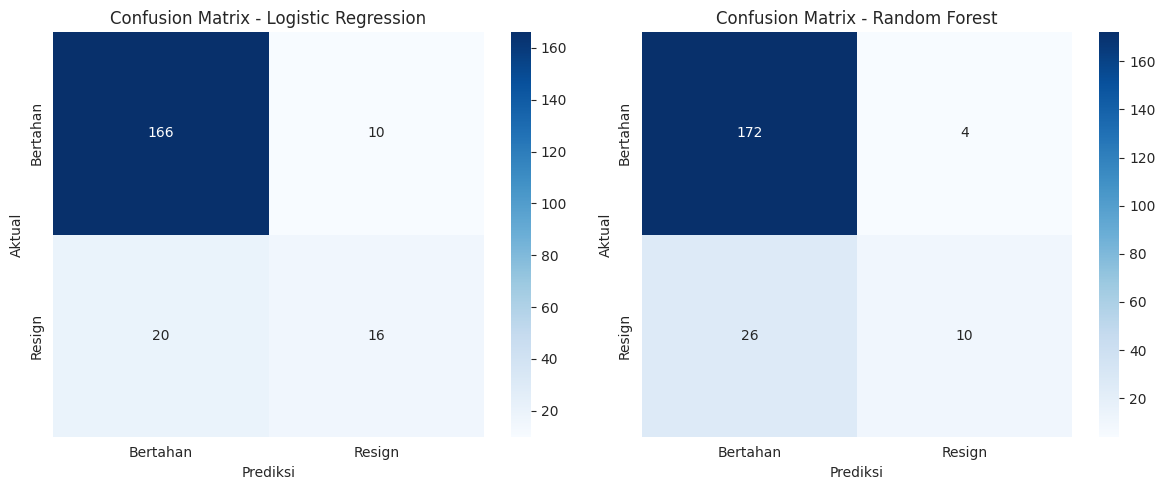

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", log_pred), ("Random Forest", rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Bertahan", "Resign"], yticklabels=["Bertahan", "Resign"])
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.savefig("dashboard_assets_confusion.png", dpi=120)
plt.show()

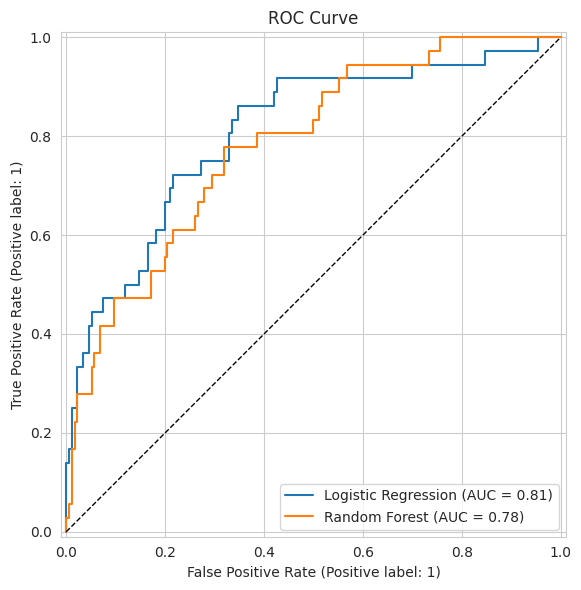

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, log_proba, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_title("ROC Curve")
plt.tight_layout()
plt.savefig("dashboard_assets_roc.png", dpi=120)
plt.show()

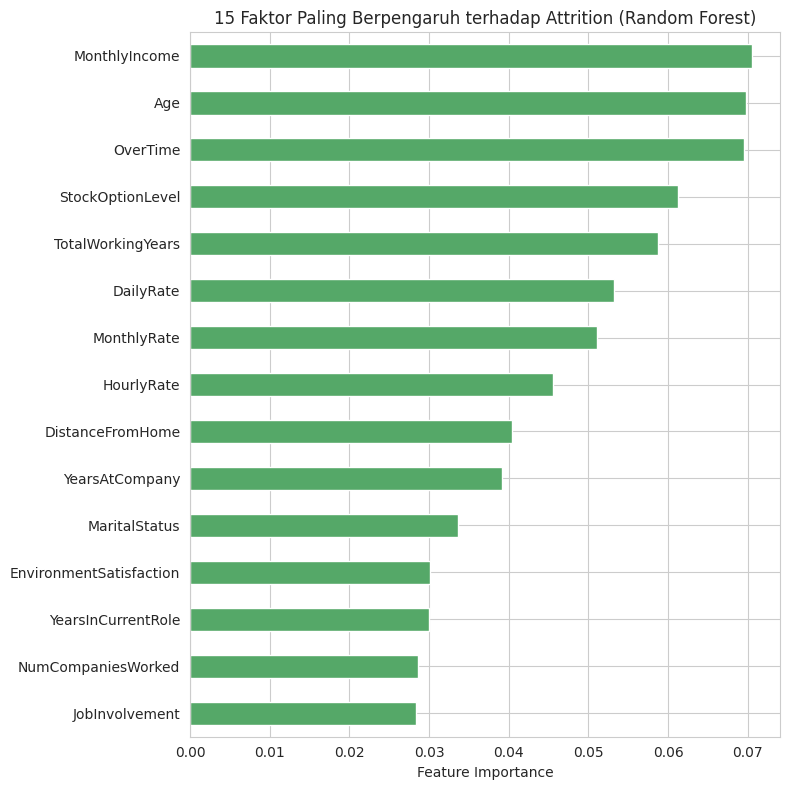

MonthlyIncome              0.070509
Age                        0.069729
OverTime                   0.069502
StockOptionLevel           0.061240
TotalWorkingYears          0.058779
DailyRate                  0.053176
MonthlyRate                0.051114
HourlyRate                 0.045493
DistanceFromHome           0.040411
YearsAtCompany             0.039140
MaritalStatus              0.033643
EnvironmentSatisfaction    0.030124
YearsInCurrentRole         0.030035
NumCompaniesWorked         0.028616
JobInvolvement             0.028377
dtype: float64

In [ ]:
# Random Forest dipilih sebagai model final karena ROC-AUC dan recall untuk kelas
# 'Resign' lebih tinggi -- penting agar HR tidak melewatkan karyawan berisiko resign.
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 8))
importances.head(15).sort_values().plot(kind="barh", color="#55A868")
plt.title("15 Faktor Paling Berpengaruh terhadap Attrition (Random Forest)")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.savefig("dashboard_assets_feature_importance.png", dpi=120)
plt.show()

importances.head(15)

**Model final: Random Forest Classifier.** Faktor paling berpengaruh terhadap attrition (berdasarkan feature importance) konsisten dengan temuan pada Data Understanding: `OverTime`, `MonthlyIncome`, `Age`, `TotalWorkingYears`, `JobRole`, `DistanceFromHome`, dan `YearsAtCompany`.

### Menyimpan model untuk deployment (prediction.py)

In [ ]:
import os
os.makedirs("model", exist_ok=True)

joblib.dump(rf, "model/rf_attrition_model.joblib")
joblib.dump(scaler, "model/scaler.joblib")   # disimpan untuk konsistensi meski RF tidak butuh scaling
joblib.dump(encoders, "model/encoders.joblib")
joblib.dump(list(X.columns), "model/feature_columns.joblib")

print("Model & artefak preprocessing tersimpan di folder 'model/'.")

Model & artefak preprocessing tersimpan di folder 'model/'.


### Memprediksi status Attrition pada 412 karyawan yang belum berlabel

In [ ]:
X_unlabeled = unlabeled_clean.drop(columns=["Attrition"])[X.columns]
pred_unlabeled = rf.predict(X_unlabeled)
proba_unlabeled = rf.predict_proba(X_unlabeled)[:, 1]

hasil_prediksi = unlabeled[["EmployeeId"]].copy()
hasil_prediksi["Predicted_Attrition"] = pred_unlabeled
hasil_prediksi["Attrition_Risk_Probability"] = proba_unlabeled.round(3)
hasil_prediksi = hasil_prediksi.sort_values("Attrition_Risk_Probability", ascending=False)
hasil_prediksi.to_csv("model/predicted_attrition_unlabeled.csv", index=False)

print(f"Jumlah karyawan diprediksi Resign: {(pred_unlabeled == 1).sum()} dari {len(pred_unlabeled)}")
hasil_prediksi.head(10)

Jumlah karyawan diprediksi Resign: 23 dari 412


,EmployeeId,Predicted_Attrition,Attrition_Risk_Probability
1214,1215,1,0.841
1060,1061,1,0.817
948,949,1,0.794
697,698,1,0.746
1246,1247,1,0.737
791,792,1,0.652
93,94,1,0.649
1103,1104,1,0.630
1096,1097,1,0.609
1151,1152,1,0.598


## Conclusion

Model Random Forest berhasil dibangun untuk mengidentifikasi karyawan berisiko resign, dengan faktor pendorong utama attrition di Jaya Jaya Maju adalah **lembur (OverTime)**, **pendapatan bulanan yang rendah**, **usia dan masa kerja yang masih muda**, **jarak rumah-kantor yang jauh**, serta **status pernikahan single dan frekuensi perjalanan dinas yang tinggi**. Karyawan pada peran **Sales Representative** dan **Laboratory Technician** memiliki risiko resign tertinggi. Hasil prediksi pada 412 karyawan yang belum berlabel disimpan pada `model/predicted_attrition_unlabeled.csv` dan dapat digunakan HR untuk melakukan intervensi dini. Detail lengkap rekomendasi action items tersedia pada berkas README.md.